# EDA — Filosofi

**Projet :** Compagnon Immobilier · **Auteur :** Cécile NAUDET · **Date :** 15/10/2026
**Fiche d'audit associée :** `CN_audit_filosofi.ipynb`

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

data = Path("/home/naude/formation/projet_compagnon/data")
filo = pd.read_parquet(data / "filosofi_commune_2014_2021.parquet")

def eta2_kruskal(groupes):
    """Kruskal-Wallis + taille d'effet eta² (part de la variabilité des rangs expliquée par les groupes)."""
    H, p = stats.kruskal(*groupes)
    k, n = len(groupes), sum(len(g) for g in groupes)
    return H, p, (H - k + 1) / (n - k)

def r_mannwhitney(a, b):
    """Mann-Whitney + taille d'effet r rang-bisérial (de -1 à 1).
    r > 0 : les valeurs de a ont tendance à être plus élevées que celles de b.
    (1 + r) / 2 = probabilité qu'une valeur tirée dans a dépasse une valeur tirée dans b."""
    U, p = stats.mannwhitneyu(a, b)
    return U, p, 2 * U / (len(a) * len(b)) - 1


# Décision de l'audit : on garde les arrondissements, on retire Paris, Lyon et Marseille en commune entière
filo = filo[~filo["code_commune"].isin(["75056", "69123", "13055"])]
print(filo.shape)

(261295, 29)


# 0. Cadre de l'analyse

**Objectif :** comprendre comment les variables de revenu se rapprochent ou se distinguent les unes des autres, puis étudier leur lien avec le prix au m².

| Élément | Choix |
|---|---|
| Source | Filosofi (Insee), revenus disponibles par commune. Voir la fiche d'audit. |
| Maille | Une ligne = une commune × une année. Paris, Lyon et Marseille par arrondissement. |
| Période | 2014-2021 (dernier millésime disponible), entièrement hors période de test (2025). |
| Cible | Prix médian au m² par commune et par année, issu de DVF+ (table cible). |
| Clé de rapprochement | `code_commune` + `annee`. |
| Points d'attention | Indicateurs détaillés publiés seulement pour les communes d'au moins 1 000 ménages ou 2 000 personnes ; codes communes à harmoniser entre millésimes. |

# B. Relations entre les variables de Filosofi

### B1. Redondances entre variables

**Variables :** les 26 variables quantitatives continues et `NBMEN`.

**Pourquoi regarder cela :** plusieurs variables risquent de porter la même information (les trois effectifs, les déciles voisins, les indicateurs d'inégalité). Repérer ces redondances permet de garder une seule variable par groupe pour la suite.

**Méthode :** matrice des corrélations de Spearman, calculée sur les communes qui ont tous les indicateurs (au moins 1 000 ménages ou 2 000 personnes). On utilise Spearman plutôt que Pearson parce que les distributions sont très asymétriques (fiche d'audit, étape 4).


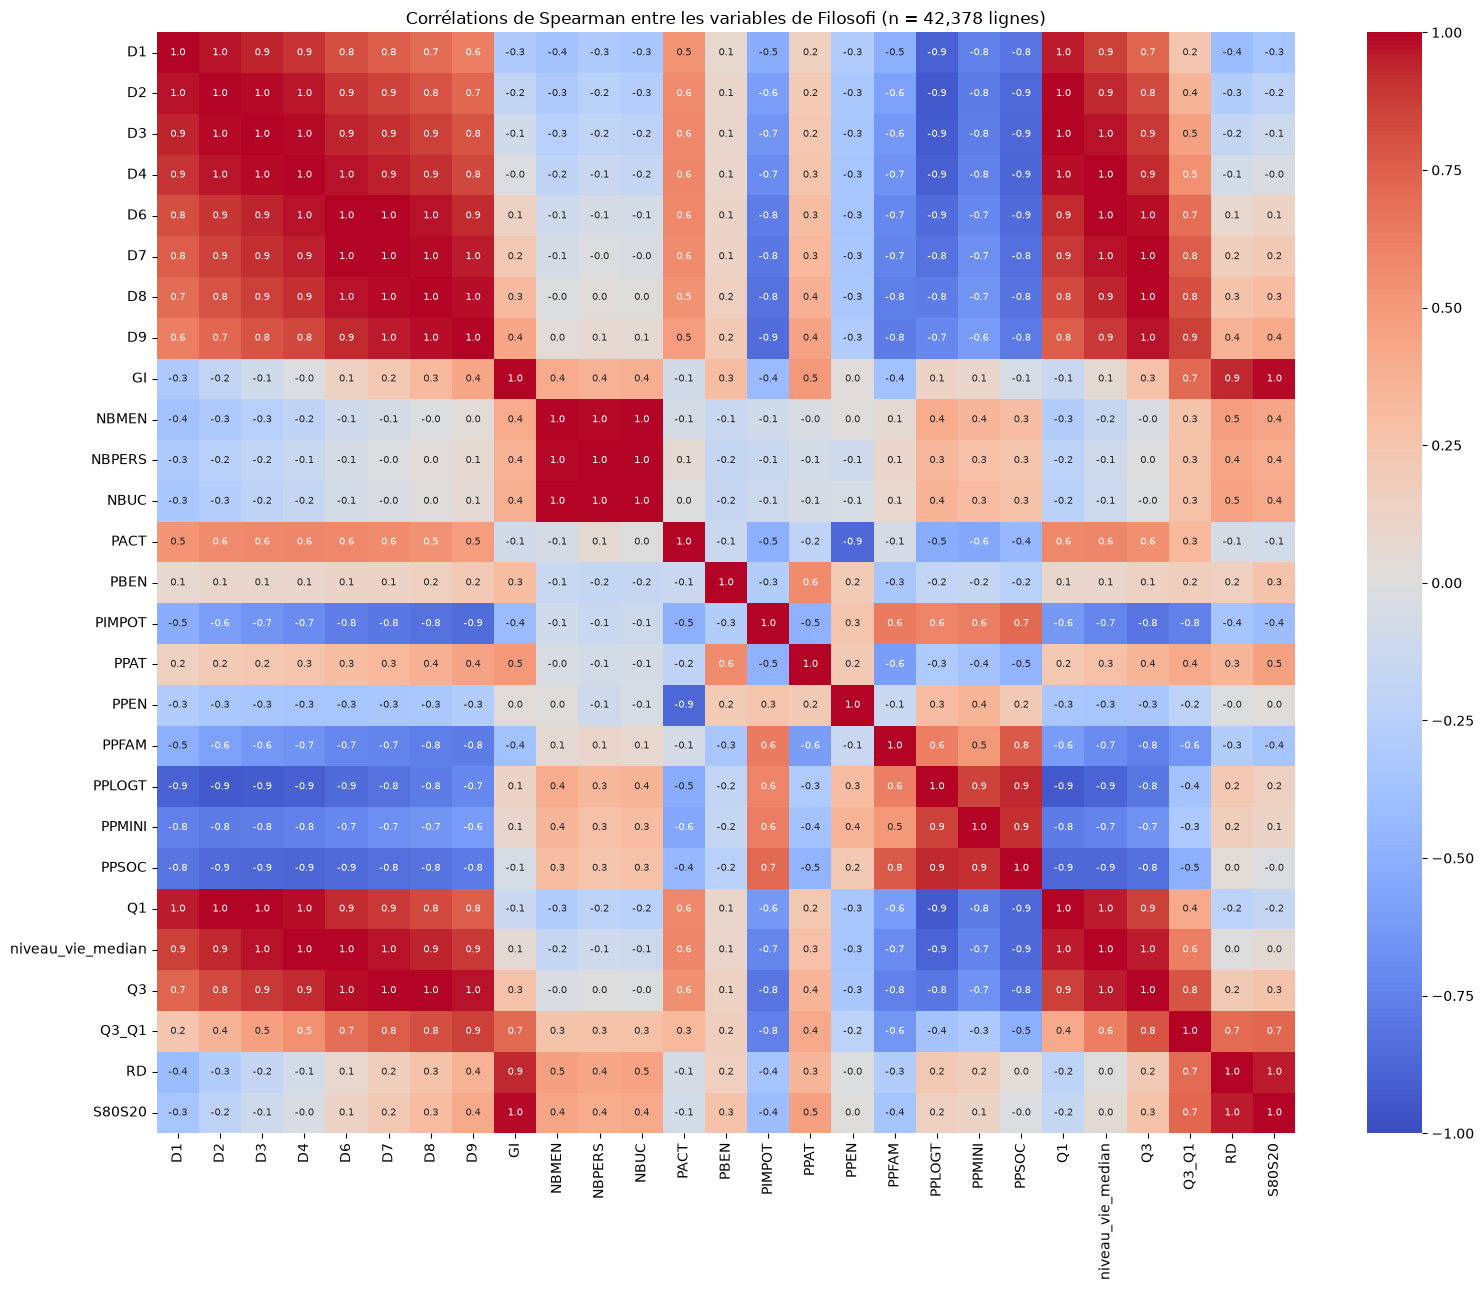

In [33]:
# Communes avec tous les indicateurs (indicateurs détaillés publiés en bloc)
complet = filo.dropna(subset=["D1"])
cols = [c for c in filo.columns if c not in ["code_commune", "annee"]]

corr = complet[cols].corr(method="spearman")

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title(f"Corrélations de Spearman entre les variables de Filosofi (n = {len(complet):,} lignes)")
plt.tight_layout()
plt.show()

**Constat :** la matrice fait apparaître des groupes de variables très liées entre elles (|rho| ≥ 0,9) :
- **Effectifs** : `NBMEN`, `NBPERS` et `NBUC` sont parfaitement liés (rho = 1,0).
- **Position dans la distribution** : les déciles voisins, les quartiles et la médiane sont liés à 0,9-1,0. Le lien s'affaiblit entre les extrêmes (D1 et D9 : 0,6) : le bas et le haut de la distribution ne racontent pas tout à fait la même chose.
- **Inégalités** : `GI`, `RD` et `S80S20` sont liés à 0,9-1,0. `Q3_Q1` est plus lié au niveau de revenu (Q3, D9 : 0,8-0,9) qu'aux inégalités (0,7), parce qu'il est exprimé en euros.
- **Prestations sociales** : `PPSOC` est lié à 0,8-0,9 avec ses sous-parts (`PPLOGT`, `PPMINI`, `PPFAM`), et à −0,9 avec la médiane : plus une commune est aisée, moins les prestations pèsent.
- **Actifs et retraités** : `PACT` et `PPEN` sont liés à −0,9. C'est la même information vue des deux côtés.
- **Impôts** : `PIMPOT` est lié à −0,9 avec D9 : les communes aux hauts revenus sont plus imposées.

Trois informations restent peu liées à la médiane :
- la **taille de la commune** (rho entre −0,2 et 0,1) ;
- les **inégalités** (`GI` : 0,1) ;
- la **part des revenus du patrimoine** (`PPAT` : 0,3).

Les grandes communes sont un peu plus inégalitaires (`NBMEN` et `GI` : 0,4).

**Interprétation :** les 27 variables se résument à environ six informations distinctes. Pour chacune, on peut garder une seule variable :

| Information | Variable proposée | Variables redondantes |
|---|---|---|
| Niveau de revenu | `niveau_vie_median` | déciles, quartiles, `PPSOC` et ses sous-parts, `PIMPOT` |
| Étendue de la distribution | `D1`, `D9` (si besoin) | déciles voisins |
| Inégalités | `GI` ou `RD` | `S80S20`, `Q3_Q1` |
| Profil actifs / retraités | `PACT` | `PPEN` |
| Patrimoine | `PPAT` | `PBEN` en partie (0,6) |
| Taille de la commune | `NBMEN` | `NBPERS`, `NBUC` |

`RD` peut être préféré au Gini : il repose sur deux déciles, donc il est moins sensible aux revenus exceptionnels (fiche d'audit, valeurs extrêmes).

**Biais / limites :** les corrélations sont calculées sur les grandes communes seulement (au moins 1 000 ménages ou 2 000 personnes). Rien ne garantit que les mêmes liens existent dans les petites communes, pour lesquelles seuls la médiane et les effectifs sont connus.

### B2. Niveau de vie médian selon la taille de la commune

**Variables :** `niveau_vie_median`, `NBMEN` (regroupé en classes de taille).

**Pourquoi regarder cela :** B1 ne portait que sur les grandes communes. La médiane et la taille sont connues pour presque toutes les communes : on peut donc regarder si le niveau de vie diffère entre petites et grandes communes, c'est-à-dire, en gros, entre rural et urbain.

**Méthode :** une seule année (2019), pour ne pas compter chaque commune huit fois. Boxplot de la médiane par classe de taille, puis test de Kruskal-Wallis (les classes ont-elles des médianes différentes ?) et corrélation de Spearman (le lien suit-il un sens ?).

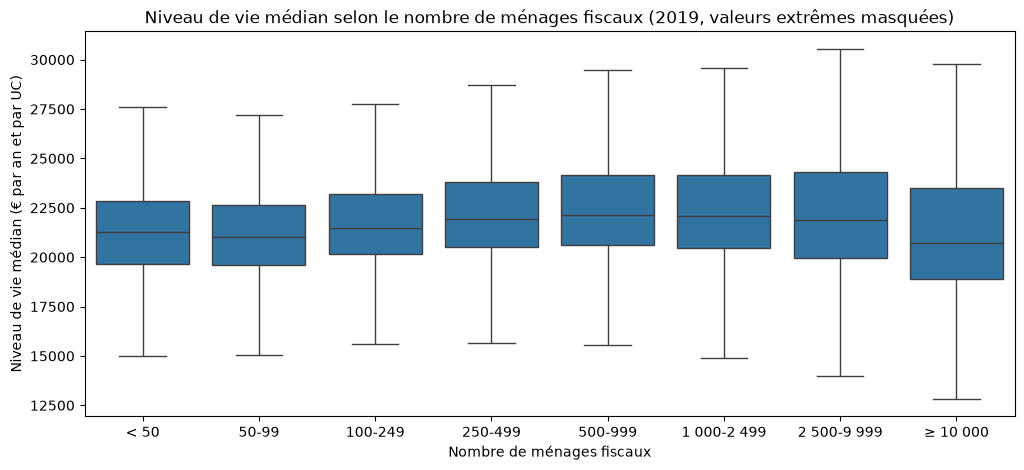

             nb_communes  mediane
taille                           
< 50                 714  21270.0
50-99               6243  21030.0
100-249             9913  21490.0
250-499             6039  21910.0
500-999             3869  22130.0
1 000-2 499         2726  22110.0
2 500-9 999         1436  21880.0
≥ 10 000             418  20705.0


In [34]:
# Une seule année : 2019, dernière année avant le changement de format des fichiers
f19 = filo[filo["annee"] == 2019].dropna(subset=["niveau_vie_median"]).copy()

bornes = [0, 50, 100, 250, 500, 1000, 2500, 10_000, float("inf")]
etiquettes = ["< 50", "50-99", "100-249", "250-499", "500-999",
              "1 000-2 499", "2 500-9 999", "≥ 10 000"]
f19["taille"] = pd.cut(f19["NBMEN"], bins=bornes, labels=etiquettes, right=False)

plt.figure(figsize=(12, 5))
sns.boxplot(data=f19, x="taille", y="niveau_vie_median", showfliers=False)
plt.title("Niveau de vie médian selon le nombre de ménages fiscaux (2019, valeurs extrêmes masquées)")
plt.xlabel("Nombre de ménages fiscaux")
plt.ylabel("Niveau de vie médian (€ par an et par UC)")
plt.show()

print(f19.groupby("taille", observed=True)["niveau_vie_median"]
         .agg(nb_communes="count", mediane="median").round(0))

In [35]:
groupes = [g["niveau_vie_median"].values for _, g in f19.groupby("taille", observed=True)]
H, p, eta2 = eta2_kruskal(groupes)
print(f"Kruskal-Wallis : p-value = {p:.1e} | eta² = {eta2:.3f}")

rho, p = stats.spearmanr(f19["NBMEN"], f19["niveau_vie_median"])
print(f"Spearman : rho = {rho:.2f} | p-value = {p:.1e} | n = {len(f19)}")

Kruskal-Wallis : p-value = 9.1e-205 | eta² = 0.031
Spearman : rho = 0.16 | p-value = 6.9e-177 | n = 31358


**Constat :**
- Le niveau de vie médian suit une légère courbe en cloche selon la taille : 21 030 € pour les communes de 50 à 99 ménages, un maximum de 22 130 € entre 500 et 999 ménages, puis 20 705 € pour les communes de 10 000 ménages et plus.
- L'écart entre classes reste faible (environ 1 400 €, soit 7 %), alors que l'écart à l'intérieur de chaque classe est bien plus grand (boîtes de 3 000 à 4 500 € de hauteur).
- La dispersion augmente avec la taille : les communes de 10 000 ménages et plus ont la boîte la plus haute et descendent jusqu'à 12 800 €.

**Résultat :**
- Kruskal-Wallis : p-value inférieure à 0,05, on rejette H0 : les classes de taille ont des niveaux de vie différents. Mais la taille d'effet est faible (η² = 0,031) : la classe de taille n'explique qu'environ 3 % des écarts de niveau de vie entre communes.
- Spearman : rho = 0,16, lien positif et faible.

**Interprétation :** les communes périurbaines de taille moyenne sont un peu plus aisées que les petites communes rurales et que les grandes villes. Mais la taille explique très peu du niveau de vie : deux communes de même taille peuvent avoir des niveaux de vie très différents. Les tests sont significatifs surtout parce que l'effectif est grand (31 358 communes) ; c'est la faiblesse de l'écart et de rho qui compte.

**Impact projet :** la taille de la commune et le niveau de vie médian portent des informations différentes ; les deux peuvent être gardés comme variables candidates.

### B3. Évolution du niveau de vie dans le temps

**Variables :** `niveau_vie_median`, `annee`.

**Pourquoi regarder cela :** le projet porte sur l'évolution des prix. Si le niveau de vie d'une commune change peu d'une année à l'autre, il pourra expliquer les écarts de prix entre communes, mais difficilement leur évolution.

**Méthode :** on garde les communes qui ont une médiane les 8 années (même code de 2014 à 2021). On trace l'évolution de la médiane des communes, puis la distribution des évolutions annuelles commune par commune. On mesure ensuite si les communes gardent leur rang (Spearman entre 2014 et 2021) et quelle part des écarts vient des différences entre communes plutôt que du temps.

Communes avec une médiane les 8 années : 30891


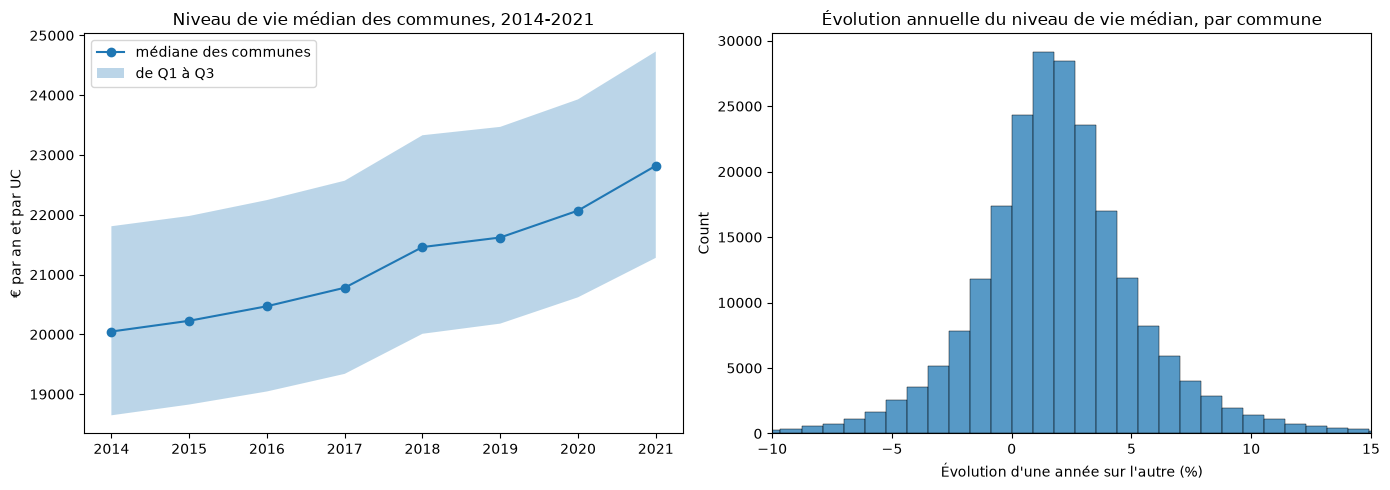

In [36]:
# Une ligne par commune, une colonne par année ; on garde les communes complètes
med = filo.pivot(index="code_commune", columns="annee", values="niveau_vie_median").dropna()
print("Communes avec une médiane les 8 années :", len(med))

# Évolution annuelle de chaque commune (%) : (année N / année N-1 - 1) × 100
evol = (med / med.shift(axis=1) - 1).iloc[:, 1:] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Médiane des communes par année, avec la bande Q1-Q3
q = med.quantile([0.25, 0.5, 0.75])
axes[0].plot(med.columns, q.loc[0.5], marker="o", label="médiane des communes")
axes[0].fill_between(med.columns, q.loc[0.25], q.loc[0.75], alpha=0.3, label="de Q1 à Q3")
axes[0].set_title("Niveau de vie médian des communes, 2014-2021")
axes[0].set_ylabel("€ par an et par UC")
axes[0].legend()

# 2. Distribution des évolutions annuelles (toutes communes, toutes années)
sns.histplot(evol.stack(), bins=100, ax=axes[1])
axes[1].set_xlim(-10, 15)
axes[1].set_title("Évolution annuelle du niveau de vie médian, par commune")
axes[1].set_xlabel("Évolution d'une année sur l'autre (%)")

plt.tight_layout()
plt.show()

In [37]:
# 1. Les communes gardent-elles leur rang entre 2014 et 2021 ?
rho, p = stats.spearmanr(med[2014], med[2021])
print(f"Spearman 2014 / 2021 : rho = {rho:.2f} | p-value = {p:.1e} | n = {len(med)}")

# 2. Part des écarts due aux différences entre communes (plutôt qu'au temps)
total = med.stack().var()
entre = med.mean(axis=1).var()
print(f"Part des écarts entre communes : {entre / total * 100:.1f} %")

# 3. Évolutions annuelles : ordre de grandeur
print("\nÉvolution annuelle (%) :")
print(evol.stack().describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1))

Spearman 2014 / 2021 : rho = 0.90 | p-value = 0.0e+00 | n = 30891
Part des écarts entre communes : 88.1 %

Évolution annuelle (%) :
count    216237.0
mean          1.9
std           3.6
min         -28.1
5%           -3.6
25%           0.0
50%           1.8
75%           3.7
95%           7.7
max          59.7
dtype: float64


**Constat :**
- Le niveau de vie médian des communes augmente régulièrement, de 20 050 € en 2014 à environ 22 800 € en 2021 (+1,9 % par an en moyenne). La hausse est plus forte entre 2017 et 2018 (environ +3 %).
- L'écart entre communes aisées et modestes s'élargit un peu : la bande de Q1 à Q3 passe d'environ 3 150 € à 3 450 €.
- Commune par commune, l'évolution annuelle est centrée sur +1,8 %, mais très dispersée (écart-type de 3,6 points ; 90 % des évolutions entre −3,6 % et +7,7 %).

**Résultat :**
- Spearman entre 2014 et 2021 : rho = 0,90, lien fort (p-value < 0,05) : les communes gardent presque le même classement sur toute la période.
- 88 % des écarts de niveau de vie viennent des différences entre communes, 12 % de l'évolution dans le temps.

**Interprétation :** le niveau de vie médian est une caractéristique stable de la commune. Sa progression annuelle est faible par rapport aux variations d'une année sur l'autre, qui relèvent en grande partie du bruit, surtout dans les petites communes.

**Biais / limites :** le saut de 2018 coïncide avec un changement de méthode de l'Insee (calcul des prestations sociales harmonisé avec l'enquête ERFS, *Sources et méthodes Filosofi 2021*) : une partie de la hausse peut venir de la méthode. Seules les communes au même code les 8 années sont prises en compte (30 891).

**Impact projet :** le niveau de vie devrait surtout expliquer les écarts de **niveau** de prix entre communes. Son lien avec l'**évolution** des prix devra être testé à part en partie C ; une évolution sur plusieurs années serait moins bruitée qu'une évolution annuelle.

# C. Relation avec la cible

### C0. Rapprochement avec la table cible

**Sources et rapprochement :** table cible `cible_commune_annee_type.parquet` (DVF+) et Filosofi, par `code_commune` + `annee`, de 2014 à 2021.

**Pourquoi regarder cela :** chaque millésime de Filosofi est publié dans la géographie de l'année suivante, et les fusions de communes changent les codes. Avant toute analyse, il faut mesurer quelle part des communes et des ventes trouve un revenu.

**Méthode :** jointure à gauche (on garde toutes les lignes de la cible), puis on distingue deux cas d'échec : code commune absent de Filosofi (problème de géographie), ou code présent mais médiane masquée (secret statistique).

In [38]:
# Table cible, années communes aux deux sources
cible = pd.read_parquet(data / "dataset_cible" / "cible_commune_annee_type.parquet")
cible = cible[cible["annee"] <= 2021].copy()
cible["n_total"] = cible["n_appart"] + cible["n_maison"]

# Jointure à gauche : on garde toutes les communes × années de la cible
fusion = cible.merge(filo, on=["code_commune", "annee"], how="left", indicator=True)

# Trois cas pour chaque ligne de la cible
fusion["cas"] = np.select(
    [fusion["_merge"] == "left_only", fusion["niveau_vie_median"].isna()],
    ["code absent de Filosofi", "médiane masquée"],
    default="revenu trouvé",
)

# Part des lignes et des ventes dans chaque cas
bilan = fusion.groupby("cas").agg(lignes=("code_commune", "size"), ventes=("n_total", "sum"))
bilan["% lignes"] = (bilan["lignes"] / bilan["lignes"].sum() * 100).round(1)
bilan["% ventes"] = (bilan["ventes"] / bilan["ventes"].sum() * 100).round(1)
display(bilan)

# Évolution par année de la part des ventes avec un revenu
par_annee = fusion.groupby("annee").apply(
    lambda d: d.loc[d["cas"] == "revenu trouvé", "n_total"].sum() / d["n_total"].sum() * 100
).round(1)
print("\n% des ventes avec un revenu, par année :")
print(par_annee)

,lignes,ventes,% lignes,% ventes
cas,,,,
code absent de Filosofi,12891,26945,5.2,0.4
médiane masquée,4433,8512,1.8,0.1
revenu trouvé,228732,6377924,93.0,99.4



% des ventes avec un revenu, par année :
annee
2014    99.6
2015    99.0
2016    99.3
2017    99.6
2018    99.4
2019    99.5
2020    99.6
2021    99.5
dtype: float64


**Constat :** 99,4 % des ventes de 2014 à 2021 trouvent un niveau de vie médian dans Filosofi, avec une part stable d'une année à l'autre (99,0 à 99,6 %). Les échecs concernent 7 % des lignes commune × année, mais seulement 0,5 % des ventes : codes communes absents de Filosofi (0,4 % des ventes, probablement des communes fusionnées ou renommées) et médianes masquées par le secret statistique (0,1 %).

**Impact projet :** les pertes sont négligeables pour l'EDA ; aucune table de passage entre géographies n'est nécessaire à ce stade. La question pourra se reposer en modélisation, si les communes concernées doivent être conservées.

### C1. Prix au m² selon le niveau de vie médian

**Sources et rapprochement :** table cible et Filosofi, par `code_commune` + `annee`, année2014, 2016,2018,2020, communes avec au moins 10 ventes du type de bien.

**Variables :** `niveau_vie_median`, `prix_m2_med_maison`, `prix_m2_med_appart`.

**Pourquoi regarder cela :** c'est la question centrale de l'EDA Filosofi : les communes où les habitants ont un niveau de vie plus élevé ont-elles des prix au m² plus élevés ?

**Méthode :**nuages de points pour 2014, 2016, 2018 et 2020, puis corrélation de Spearman pour chacune des 8 années, avec le même seuil de 10 ventes.

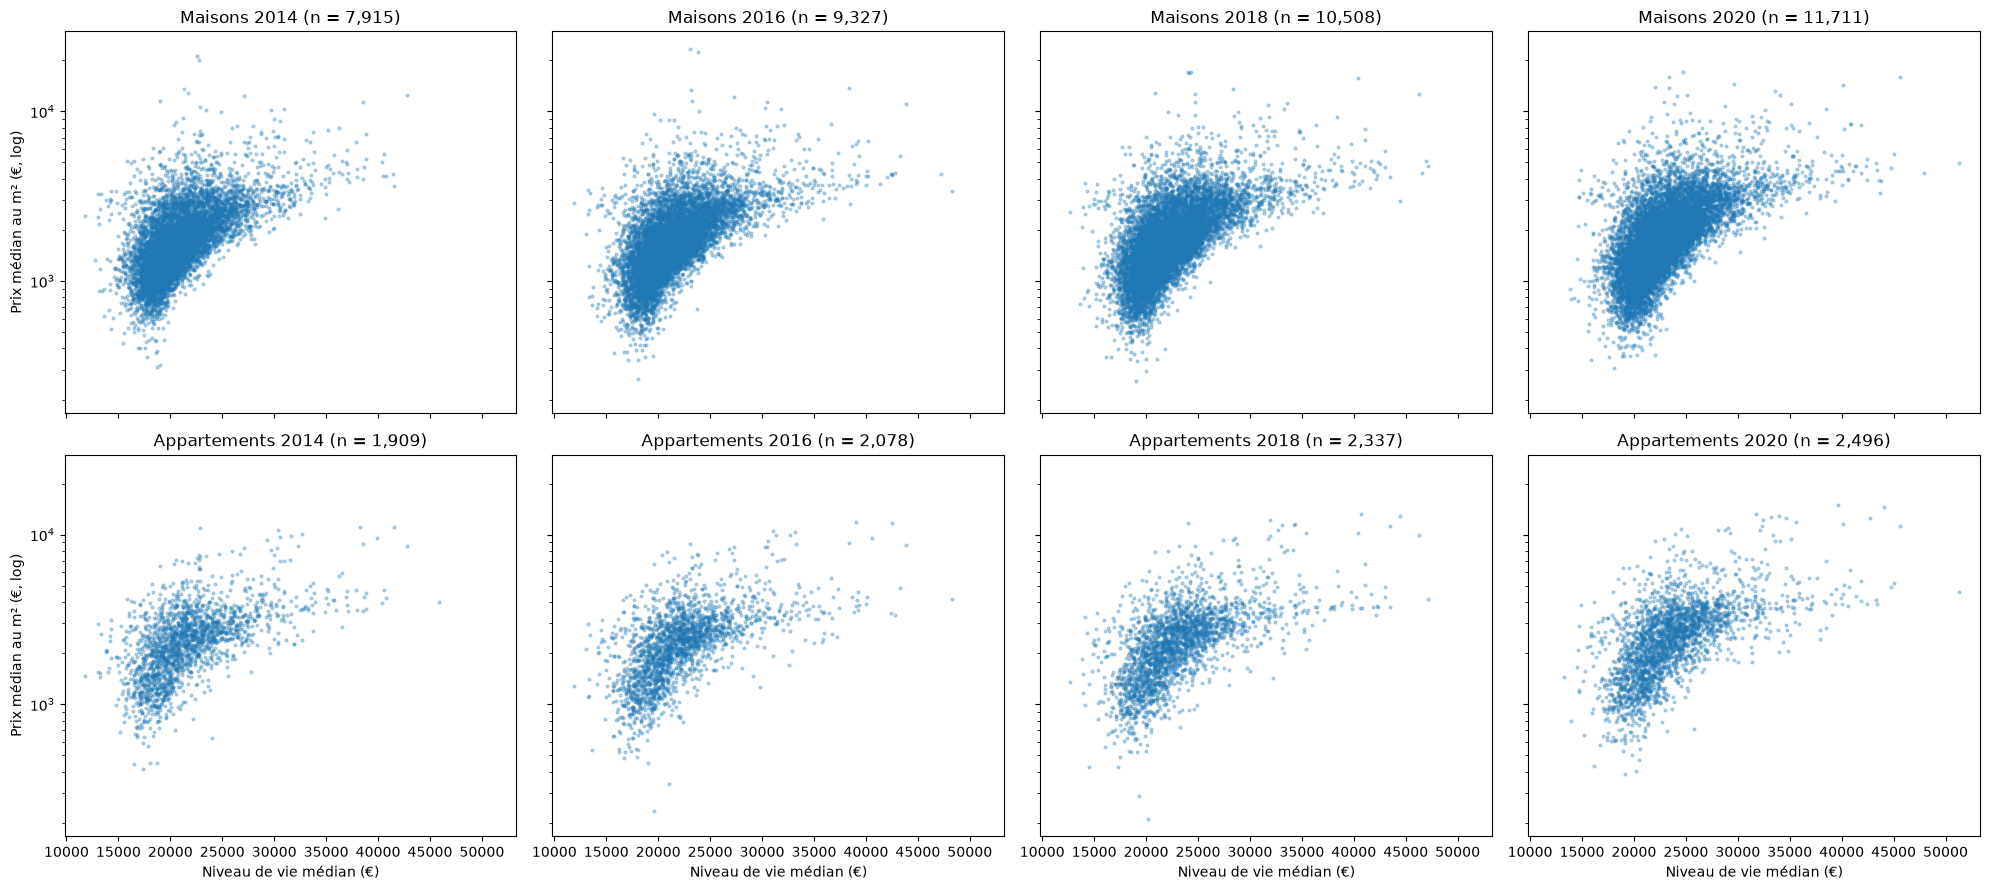

In [39]:
annees = [2014, 2016, 2018, 2020]
types = [("maison", "Maisons"), ("appart", "Appartements")]

fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True)
for i, (t, nom) in enumerate(types):
    for j, an in enumerate(annees):
        d = fusion[(fusion["annee"] == an) & (fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)]
        ax = axes[i, j]
        ax.scatter(d["niveau_vie_median"], d[f"prix_m2_med_{t}"], s=4, alpha=0.3)
        ax.set_yscale("log")
        ax.set_title(f"{nom} {an} (n = {len(d):,})")
        if j == 0:
            ax.set_ylabel("Prix médian au m² (€, log)")
        if i == 1:
            ax.set_xlabel("Niveau de vie médian (€)")
plt.tight_layout()
plt.show()

**Constat :**
- Pour les maisons comme pour les appartements, le prix médian au m² augmente avec le niveau de vie médian de la commune : le nuage de points monte de gauche à droite.
- Le lien n'est pas une droite : le prix monte nettement pour les niveaux de vie modestes à moyens, puis le nuage s'élargit et monte moins régulièrement pour les communes les plus aisées.
- La dispersion est forte : à niveau de vie égal, le prix au m² peut être très différent d'une commune à l'autre.
- Quelques communes ont un niveau de vie modeste et des prix élevés.
- L'analyse porte sur 11 386 communes pour les maisons, mais seulement 2 450 pour les appartements : il faut au moins 10 ventes d'appartements, ce qui concerne surtout les communes urbaines.

**Hypothèse :** il existe un lien positif entre le niveau de vie des habitants et le prix au m², pour les deux types de biens. Une partie importante des écarts dépend aussi de la localisation (région, littoral, proximité d'une grande ville).

**Méthode de vérification :** corrélation de Spearman pour chaque type de bien. Elle mesure si les deux variables augmentent ensemble, sans supposer que le lien est une droite, et elle est peu sensible aux valeurs extrêmes. Taille d'effet : rho.

In [40]:
lignes = []
for an in range(2014, 2022):
    for t, nom in types:
        d = fusion[(fusion["annee"] == an) & (fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)]
        rho, p = stats.spearmanr(d["niveau_vie_median"], d[f"prix_m2_med_{t}"])
        lignes.append({"annee": an, "type": nom, "rho": round(rho, 2), "n": len(d)})

rho_annees = pd.DataFrame(lignes).pivot(index="annee", columns="type", values=["rho", "n"])
display(rho_annees)

rho                    n         
type  Appartements Maisons Appartements  Maisons
annee                                           
2014          0.61    0.62       1909.0   7915.0
2015          0.62    0.64       2029.0   8964.0
2016          0.64    0.65       2078.0   9327.0
2017          0.64    0.66       2263.0  10525.0
2018          0.65    0.65       2337.0  10508.0
2019          0.66    0.66       2450.0  11386.0
2020          0.65    0.66       2496.0  11711.0
2021          0.65    0.66       2730.0  13360.0

**Résultat :** pour les maisons comme pour les appartements, la p-value est inférieure à 0,05 : on rejette H0, il existe un lien entre le niveau de vie et le prix au m². Ce lien est positif et fort : rho = 0,66 pour les deux types de biens en 2019 (11 386 communes pour les maisons, 2 450 pour les appartements). Il est stable de 2014 à 2021 (voir la vérification sur plusieurs années).

**Interprétation :** plus les habitants d'une commune ont un niveau de vie élevé, plus le prix au m² y est élevé. Le lien est fort mais pas parfait : à niveau de vie égal, les prix restent très différents d'une commune à l'autre.

**Avis métier :** c'est logique : dans une commune aisée, les acheteurs peuvent payer plus cher. Mais le lien peut aussi aller dans l'autre sens : quand les prix sont élevés, seuls les ménages aisés peuvent venir s'installer. On ne peut donc pas dire que le revenu « cause » le prix. Les communes modestes aux prix élevés sont peut-être proches d'une grande ville ou sur le littoral, où la localisation compterait plus que le revenu des habitants (hypothèse à vérifier).

**Impact projet :** le niveau de vie médian est une variable candidate intéressante pour le modèle, pour les maisons comme pour les appartements.

**Action envisagée :**
- vérifier en C2 si le niveau de vie est aussi lié à l'**évolution** des prix, et pas seulement à leur niveau (B3 a montré que le niveau de vie change peu dans le temps) ;
- dans le modèle, associer le niveau de vie à une variable de localisation (le département, par exemple), pour séparer les deux effets.

**Biais / limites :**
- seules les communes avec au moins 10 ventes sont prises en compte : pour les appartements, ce sont surtout des communes urbaines ;
- Filosofi décrit les habitants de la commune, pas les acheteurs ;
- une corrélation ne prouve pas une relation de cause à effet.

### C2. Évolution des prix et du niveau de vie

**Sources et rapprochement :** table cible et Filosofi, par `code_commune` + `annee`, de 2014 à 2021.

**Variables :** `prix_m2_med_maison`, `prix_m2_med_appart`, `niveau_vie_median`.

**Pourquoi regarder cela :** C1 a montré que les communes aisées ont des prix plus élevés. Mais le projet porte sur l'évolution des prix. On veut savoir si les prix et le niveau de vie évoluent de la même façon dans le temps.

**Méthode :** on suit les mêmes communes de 2014 à 2021 (au moins 10 ventes chaque année). Pour chaque année, on calcule la médiane des prix et des niveaux de vie de ces communes, puis on les transforme en indice (base 100 en 2014) pour pouvoir comparer leurs évolutions sur un même axe.

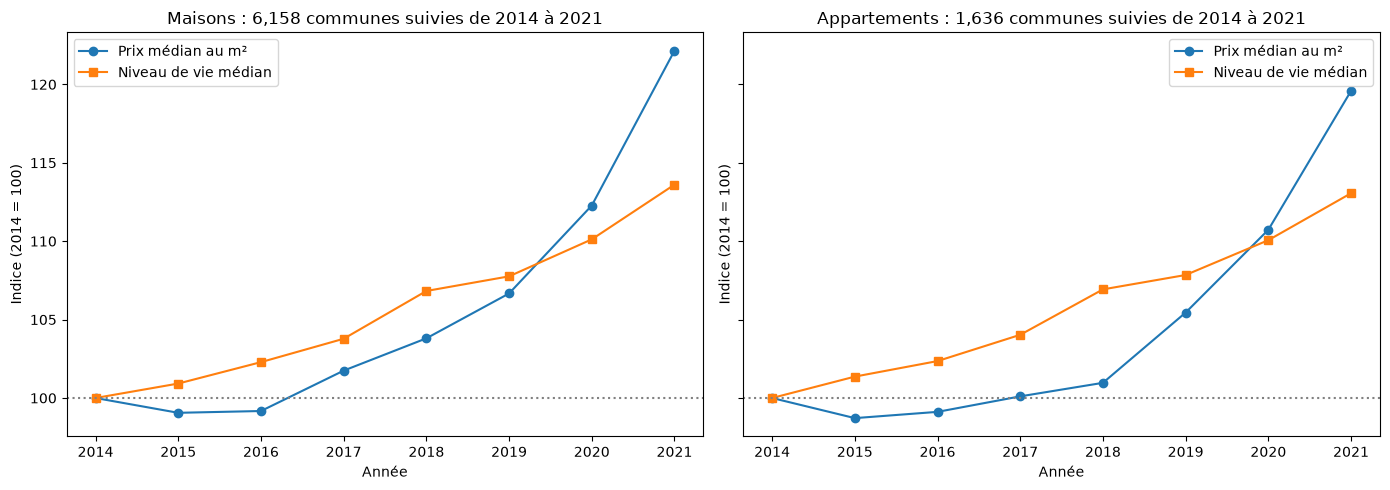

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (t, nom) in zip(axes, [("maison", "Maisons"), ("appart", "Appartements")]):
    d = fusion[(fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)]

    # On suit les mêmes communes chaque année (au moins 10 ventes les 8 années),
    # sinon la courbe changerait aussi parce que les communes changent
    nb_annees = d.groupby("code_commune")["annee"].nunique()
    d = d[d["code_commune"].isin(nb_annees[nb_annees == 8].index)]

    # Médiane des communes chaque année, puis indice base 100 en 2014
    serie = d.groupby("annee")[[f"prix_m2_med_{t}", "niveau_vie_median"]].median()
    indice = serie / serie.loc[2014] * 100

    ax.plot(indice.index, indice[f"prix_m2_med_{t}"], marker="o", label="Prix médian au m²")
    ax.plot(indice.index, indice["niveau_vie_median"], marker="s", label="Niveau de vie médian")
    ax.axhline(100, color="grey", ls=":")
    ax.set_title(f"{nom} : {d['code_commune'].nunique():,} communes suivies de 2014 à 2021")
    ax.set_xlabel("Année")
    ax.set_ylabel("Indice (2014 = 100)")
    ax.legend()

plt.tight_layout()
plt.show()

**Constat :**
- Sur les mêmes communes suivies de 2014 à 2021, le niveau de vie médian augmente régulièrement, presque en ligne droite.
- Le prix médian au m² suit une autre forme : il stagne ou recule légèrement jusqu'en 2016, puis augmente de plus en plus vite, surtout à partir de 2019.
- Les deux courbes se croisent vers 2019 pour les maisons et vers 2020 pour les appartements : avant, les revenus augmentent plus vite que les prix ; après, les prix augmentent plus vite que les revenus.

**Hypothèse :** il n'y a pas de lien entre l'évolution du niveau de vie d'une commune et l'évolution de ses prix.

**Méthode de vérification :** pour chaque commune, on calcule l'évolution du prix au m² et l'évolution du niveau de vie entre 2014 et 2021. On mesure le lien entre les deux avec une corrélation de Spearman, pour chaque type de bien. Comme le lien est presque toujours significatif avec autant de communes, on conclut sur la taille d'effet (rho). On calcule aussi le lien entre le niveau de vie de départ (2014) et l'évolution des prix, pour comparer.

In [42]:
def evolution(t, debut, fin):
    """Une ligne par commune : prix et niveau de vie au début et à la fin de la période, et leurs évolutions (%)."""
    cols = ["code_commune", f"n_{t}", f"prix_m2_med_{t}", "niveau_vie_median"]
    a = fusion.loc[fusion["annee"] == debut, cols]
    b = fusion.loc[fusion["annee"] == fin, cols]
    d = a.merge(b, on="code_commune", suffixes=("_debut", "_fin"))
    d = d[(d[f"n_{t}_debut"] >= 10) & (d[f"n_{t}_fin"] >= 10)].dropna()
    d["evol_prix"] = (d[f"prix_m2_med_{t}_fin"] / d[f"prix_m2_med_{t}_debut"] - 1) * 100
    d["evol_nv"] = (d["niveau_vie_median_fin"] / d["niveau_vie_median_debut"] - 1) * 100
    return d

evo = {"Maisons": evolution("maison", 2014, 2021),
       "Appartements": evolution("appart", 2014, 2021)}

for nom, d in evo.items():
    rho_niv, p_niv = stats.spearmanr(d["niveau_vie_median_debut"], d["evol_prix"])
    rho_evo, p_evo = stats.spearmanr(d["evol_nv"], d["evol_prix"])
    print(f"{nom} (n = {len(d)} communes)")
    print(f"  niveau de vie 2014         / évolution des prix : rho = {rho_niv:.2f} | p-value = {p_niv:.1e}")
    print(f"  évolution du niveau de vie / évolution des prix : rho = {rho_evo:.2f} | p-value = {p_evo:.1e}")

Maisons (n = 7586 communes)
  niveau de vie 2014         / évolution des prix : rho = 0.18 | p-value = 1.2e-58
  évolution du niveau de vie / évolution des prix : rho = 0.14 | p-value = 4.7e-36
Appartements (n = 1829 communes)
  niveau de vie 2014         / évolution des prix : rho = 0.21 | p-value = 8.0e-19
  évolution du niveau de vie / évolution des prix : rho = 0.20 | p-value = 9.1e-19


**Résultat :**
- Maisons (7 586 communes) : le lien entre l'évolution du niveau de vie et l'évolution des prix est positif mais faible (rho = 0,14 ; p-value < 0,05). Le lien entre le niveau de vie de départ et l'évolution des prix est aussi faible (rho = 0,18).
- Appartements (1 829 communes) : liens faibles également (rho = 0,20 et 0,21 ; p-value < 0,05).

L'hypothèse d'une absence de lien n'est donc pas confirmée : un lien existe, mais il est faible, bien plus faible que celui entre le niveau de vie et le niveau des prix (rho = 0,66 en C1).

**Interprétation :** le niveau de vie explique surtout **où** les prix sont élevés, et beaucoup moins **comment** ils évoluent. Les prix ont un peu plus augmenté dans les communes aisées et dans celles où le niveau de vie a progressé, mais cet effet reste faible.

**Avis métier :** l'évolution des prix dépend sans doute d'abord de facteurs communs à tout le pays (taux d'emprunt, crise sanitaire), qui ont fait monter les prix partout à partir de 2019, alors que le niveau de vie progressait régulièrement.

**Impact projet :** le niveau de vie est une variable utile pour le niveau des prix, mais pas suffisante pour prédire leur évolution. D'autres variables seront nécessaires, en premier lieu les taux d'emprunt.

**Action envisagée :** étudier le lien entre l'évolution des prix et les taux d'emprunt mensuels (prochaine source).

**Biais / limites :**
- l'évolution du niveau de vie d'une commune est bruitée (B3), ce qui affaiblit la corrélation mesurée : le lien réel est peut-être un peu plus fort ;
- seules les communes avec au moins 10 ventes en 2014 et en 2021 sont prises en compte ;
- une corrélation ne prouve pas une relation de cause à effet.
- Filosofi s'arrête en 2021. Le retournement du marché observé dans DVF+ (pic des ventes en 2021, puis baisse nette en 2022 et 2023) se situe donc en dehors de la période où l'on peut comparer prix et niveau de vie. On ne peut pas vérifier si le lien entre niveau de vie et prix a changé pendant ce retournement.

### C3. Comparaison géographique : prix des maisons et niveau de vie

**Sources et rapprochement :** table cible et Filosofi, par `code_commune` + `annee`, année 2019, communes avec au moins 10 ventes de maisons ; regroupement par département.

**Variables :** `prix_m2_med_maison`, `niveau_vie_median`, département (deux premiers caractères du code commune).

**Pourquoi regarder cela :** C1 a montré un lien fort entre niveau de vie et prix au m². On veut voir si les départements les plus chers sont aussi les plus aisés, ou si certaines zones font exception.

**Méthode :** pour chaque département, médiane des prix et médiane des niveaux de vie de ses communes. Les départements sont classés en 5 groupes de même taille pour chaque variable, et affichés sur deux cartes avec les mêmes couleurs.

maisons : 93 départements, de 7 à 416 communes par département
appartements : 93 départements, de 1 à 110 communes par département


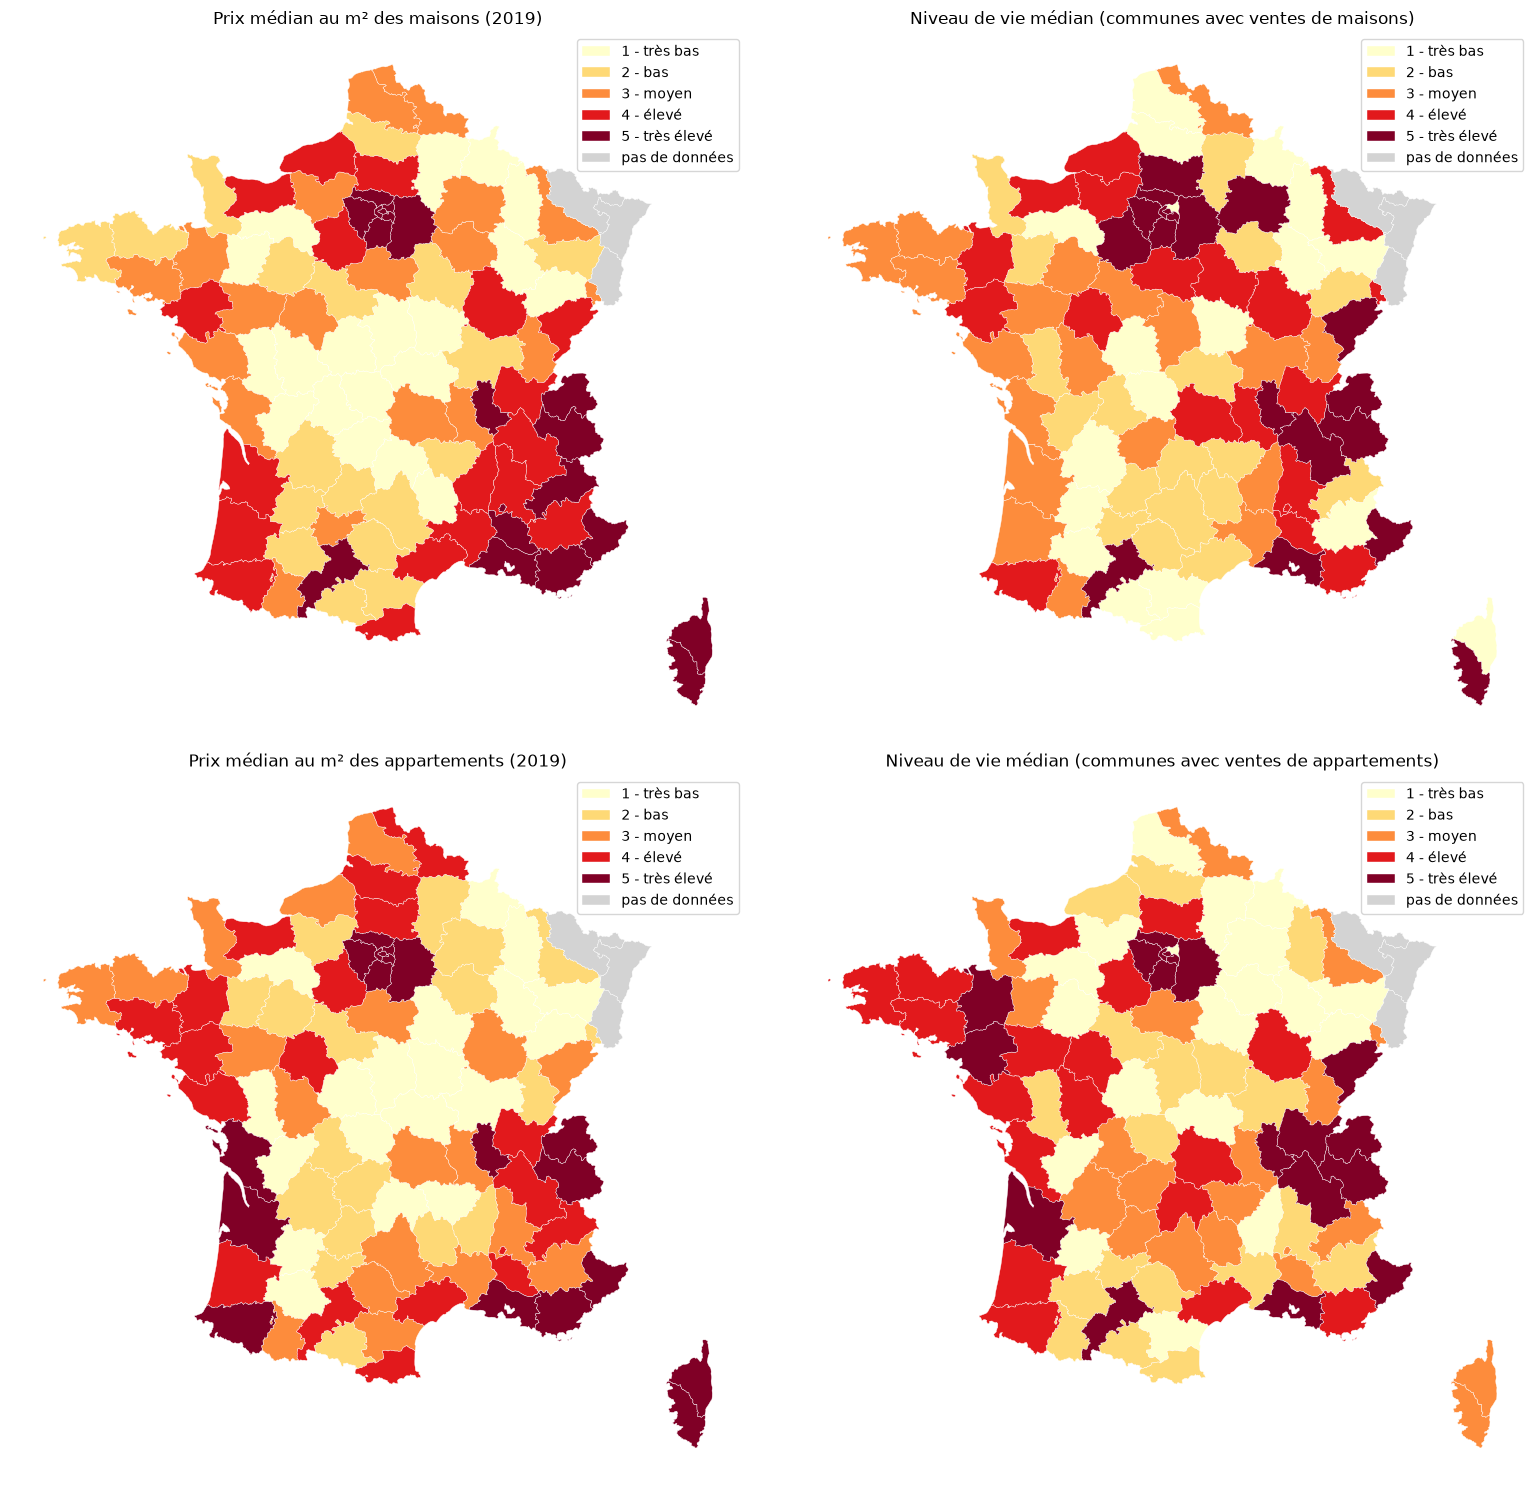

In [43]:
import geopandas as gpd

url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
deps = gpd.read_file(url)

groupes = ["1 - très bas", "2 - bas", "3 - moyen", "4 - élevé", "5 - très élevé"]
fig, axes = plt.subplots(2, 2, figsize=(16, 15))

for i, (t, nom) in enumerate([("maison", "maisons"), ("appart", "appartements")]):
    # Communes de 2019 avec au moins 10 ventes du type de bien et un niveau de vie connu
    d = fusion[(fusion["annee"] == 2019) & (fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)].copy()
    d["dep"] = d["code_commune"].str[:2]

    # Une ligne par département : médiane des communes
    par_dep = (d.groupby("dep")
                 .agg(prix=(f"prix_m2_med_{t}", "median"),
                      niveau_vie=("niveau_vie_median", "median"),
                      nb_communes=("code_commune", "size"))
                 .reset_index())

    carte = deps.merge(par_dep, left_on="code", right_on="dep", how="left")
    carte["classe_prix"] = pd.qcut(carte["prix"], 5, labels=groupes)
    carte["classe_nv"] = pd.qcut(carte["niveau_vie"], 5, labels=groupes)

    for j, (col, titre) in enumerate([("classe_prix", f"Prix médian au m² des {nom} (2019)"),
                                      ("classe_nv", f"Niveau de vie médian (communes avec ventes de {nom})")]):
        ax = axes[i, j]
        carte.plot(column=col, cmap="YlOrRd", legend=True, ax=ax,
                   edgecolor="white", linewidth=0.3,
                   missing_kwds={"color": "lightgrey", "label": "pas de données"})
        ax.set_title(titre)
        ax.set_axis_off()

    print(f"{nom} : {par_dep['dep'].nunique()} départements, de {par_dep['nb_communes'].min()} "
          f"à {par_dep['nb_communes'].max()} communes par département")

plt.tight_layout()
plt.show()

**Constat :**

*Maisons*
- Plusieurs zones sont foncées sur les deux cartes, donc à la fois chères et aisées : l'Île-de-France, les Alpes du Nord et la région lyonnaise, la Côte d'Azur, et autour de Toulouse.
- Le centre de la France est clair sur les deux cartes : prix bas et niveau de vie modeste.
- Certaines zones ne concordent pas :
  - le littoral méditerranéen (de l'Hérault aux Pyrénées-Orientales) et la Corse ont des prix élevés, mais un niveau de vie moyen ou bas ;
  - à l'inverse, une partie du Nord-Est a un niveau de vie élevé mais des prix bas.

*Appartements*
- Les deux cartes se ressemblent davantage : l'Île-de-France, la façade atlantique, les Alpes du Nord et la Côte d'Azur sont foncées sur les deux.
- Les exceptions sont moins nombreuses que pour les maisons.

*Pour les deux types* : l'Alsace-Moselle est en gris (absente de DVF+).

**Hypothèse :** au niveau des départements, les prix et le niveau de vie sont liés, et ce lien est plus fort pour les appartements que pour les maisons. Pour les maisons, d'autres facteurs comme l'attrait touristique du littoral ou l'éloignement des grandes villes pèseraient davantage.

**Méthode de vérification :** pour chaque type de bien, corrélation de Spearman entre le prix médian et le niveau de vie médian des départements. On compare ensuite les deux valeurs de rho.

In [44]:
# Test 1 : lien entre prix et niveau de vie au niveau des départements, pour chaque type de bien
for t, nom in [("maison", "Maisons"), ("appart", "Appartements")]:
    d = fusion[(fusion["annee"] == 2019) & (fusion["cas"] == "revenu trouvé") & (fusion[f"n_{t}"] >= 10)].copy()
    d["dep"] = d["code_commune"].str[:2]

    # Une ligne par département : médiane des communes
    pdep = d.groupby("dep").agg(prix=(f"prix_m2_med_{t}", "median"),
                                niveau_vie=("niveau_vie_median", "median"))

    rho, p = stats.spearmanr(pdep["prix"], pdep["niveau_vie"])
    print(f"{nom} : rho = {rho:.2f} | p-value = {p:.1e} | n = {len(pdep)} départements")

Maisons : rho = 0.66 | p-value = 5.7e-13 | n = 93 départements
Appartements : rho = 0.73 | p-value = 1.5e-16 | n = 93 départements


**Résultat :** pour les deux types de biens, la p-value est inférieure à 0,05 : on rejette H0, il existe un lien entre le prix médian et le niveau de vie médian des départements. Ce lien est positif et fort : rho = 0,66 pour les maisons et rho = 0,73 pour les appartements (93 départements).

**Interprétation :** les départements les plus aisés sont en général les plus chers, pour les maisons comme pour les appartements. Le lien est un peu plus fort pour les appartements, ce qui va dans le sens des cartes, mais l'écart entre les deux valeurs est faible : avec seulement 93 départements, on ne peut pas affirmer qu'il est réel.

**Avis métier :** les exceptions visibles sur les cartes, surtout pour les maisons, correspondent à des zones où d'autres facteurs comptent : l'attrait touristique (littoral méditerranéen, Corse), qui fait monter les prix sans lien avec le revenu des habitants, ou l'éloignement des grandes villes, qui les maintient bas malgré un niveau de vie correct (hypothèses).

**Impact projet :** le niveau de vie résume bien une partie de la géographie des prix, mais pas toute. Une variable de localisation (département ou bassin de vie) reste nécessaire dans le modèle pour capter les zones qui font exception.

**Action envisagée :** dans la suite du projet, regarder si des variables comme la part de résidences secondaires ou la distance à une grande ville expliquent les exceptions (sources à identifier avec l'équipe).

**Biais / limites :**
- une seule année (2019) ;
- chaque département est résumé par la médiane de ses communes, sans tenir compte de leur nombre d'habitants ni de leur nombre de ventes ;
- la carte du niveau de vie des appartements ne porte que sur les communes avec au moins 10 ventes d'appartements, surtout urbaines ;
- l'Alsace-Moselle n'est pas couverte.

# Synthèse

| Constat majeur | Preuve | Conséquence projet | Action |
|---|---|---|---|
| Les 27 variables se résument à environ six informations distinctes | B1 : groupes de variables liées à 0,9-1,0 | Une seule variable par groupe suffit | Retenir une variable par information (voir tableau suivant) |
| La taille de la commune explique très peu le niveau de vie | B2 : η² = 0,031 (faible), rho = 0,16 (faible) | Taille et niveau de vie portent des informations différentes | Les deux peuvent rester candidates |
| Le niveau de vie d'une commune change peu dans le temps | B3 : rho = 0,90 entre 2014 et 2021 ; 88 % des écarts viennent des différences entre communes | Il décrit surtout **quelle** commune, peu **quand** ; sa valeur peut être prolongée sans grande erreur | Prolonger la valeur 2021 si la variable est retenue |
| Presque toutes les ventes trouvent un niveau de vie | C0 : 99,4 % des ventes 2014-2021 | Pas de perte significative à la jointure | Aucune table de passage nécessaire pour l'EDA |
| Le niveau de vie est fortement lié au **niveau** des prix | C1 : rho = 0,66 (fort) pour les maisons et les appartements, stable de 2014 à 2021 | Variable informative pour expliquer où les prix sont élevés | Variable candidate |
| Le niveau de vie est faiblement lié à l'**évolution** des prix | C2 : rho de 0,14 à 0,21 (faible) entre 2014 et 2021 | Il ne suffit pas à expliquer l'évolution des prix | Chercher d'autres variables d'évolution (taux d'emprunt) |
| Les prix et le niveau de vie n'évoluent pas au même rythme | C2 : indice base 100, les prix accélèrent à partir de 2019 alors que le niveau de vie progresse régulièrement | L'accélération des prix vient d'autres facteurs | Étudier les taux d'emprunt |
| Les départements aisés sont en général les plus chers, avec des exceptions | C3 : rho = 0,66 (maisons) et 0,73 (appartements) sur 93 départements ; exceptions sur le littoral méditerranéen, en Corse et dans le Nord-Est | Le niveau de vie ne remplace pas une variable de localisation | Garder une variable de localisation dans le modèle |

## Variables candidates pour la modélisation

| Variable envisagée | Construite à partir de | Maille | Disponible a priori ? | Justification |
|---|---|---|---|---|
| Niveau de vie médian | `niveau_vie_median` | commune, à agréger au bassin de vie | Oui, avec un décalage de publication d'environ deux ans | C1, C3 : lien fort avec le niveau des prix ; B3 : très stable |
| Taille de la commune | `NBMEN` | commune | Oui | B2 : information différente du niveau de vie |
| Évolution du niveau de vie | `niveau_vie_median` sur plusieurs années | commune | Oui, avec décalage | C2 : lien faible avec l'évolution des prix ; à évaluer seulement si la variable principale est retenue |

À discuter : Filosofi est publié environ deux ans après l'année des revenus (voir décisions ouvertes)

## Prérequis à l'intégration

- **Clé et format :** `code_commune` en texte sur 5 caractères + `annee`.
- **Paris, Lyon, Marseille :** garder les arrondissements (codes utilisés par DVF+) et retirer les communes entières (75056, 69123, 13055).
- **Maille :** le niveau de vie médian ne s'additionne pas. Pour passer au bassin de vie, utiliser les données publiées directement par l'Insee à cette maille, ou une moyenne des communes pondérée par leur nombre d'habitants (approximation).
- **Période / millésime :** Filosofi couvre 2014-2021 ; l'Insee ne produira pas le millésime 2022. Les années 2022 à 2025 de DVF+ n'ont pas de niveau de vie.
- **Couverture :** 99,4 % des ventes trouvent un niveau de vie ; les 0,6 % restants sont des codes absents (communes fusionnées ou renommées) et des médianes masquées.

## À traiter au preprocessing (si la variable est retenue)

- retirer Paris, Lyon et Marseille en commune entière ;
- prolonger la valeur de 2021 pour les années 2022 à 2025 (B3 montre que le niveau de vie change peu) ;
- agréger au bassin de vie selon la méthode choisie.

## Hypothèses reportées au journal

- L'accélération des prix commence dès 2019, avant la crise sanitaire : hypothèse d'un effet des taux d'emprunt bas, que la crise sanitaire aurait amplifié à partir de 2020. À vérifier avec les taux mensuels.
- Le marché change de régime à partir de 2022 (baisse des ventes après le pic de 2021) : hypothèse d'une remontée des taux. Cette période n'est pas couverte par Filosofi.
- Les exceptions géographiques (littoral méditerranéen, Corse, Nord-Est) viendraient de l'attrait touristique ou de l'éloignement des grandes villes.
- La hausse plus forte du niveau de vie en 2018 pourrait venir en partie d'un changement de méthode de l'Insee (calcul des prestations sociales).

## Dette reportée (analyses non faites et pourquoi)

- Lien entre les indicateurs détaillés (inégalités, profil actifs / retraités, patrimoine) et les prix : non étudié, car ils ne couvrent que les grandes communes ; à faire à la maille bassin de vie si elle est retenue.
- Apport du niveau de vie **en plus** du prix de l'année précédente : non mesurable en EDA, à tester en modélisation.
- Analyse à la maille bassin de vie : en attente de la table de passage commune → bassin de vie.

## Décisions ouvertes (à discuter en groupe)

**Faut-il garder le niveau de vie dans le modèle ?**

L'EDA montre un lien fort avec le niveau des prix, mais faible avec leur évolution, qui est la question du projet. Elle ne permet pas de savoir si la variable apporte une information en plus des autres, en particulier du prix de l'année précédente, qui décrit déjà les communes chères.

- **Option 1 — la garder comme variable candidate secondaire** et décider en modélisation avec une étude d'ablation : entraîner le modèle avec et sans la variable, puis comparer l'erreur sur la période de validation. On la retire si l'erreur ne baisse pas. Coût faible en apparence : une seule variable, 99,4 % des ventes couvertes, valeur stable donc facile à prolonger.
- **Option 2 — l'écarter dès maintenant** et donner la priorité à la localisation, au prix de l'année précédente et aux taux d'emprunt. Son intégration poserait plusieurs problèmes à gérer pour un apport attendu faible sur l'évolution des prix : absence de données après 2021, choix de l'année à associer aux ventes, passage au bassin de vie. La variable pourra être réintroduite en appui si le modèle peine à expliquer les écarts entre territoires. Ce choix est une question de priorité, pas une absence de lien.

**Avis de l'auteur :** option 2, à valider avec le mentor.

**Quelle année de niveau de vie associer aux ventes de l'année N ?** (question à poser au mentor, seulement si la variable est conservée)

Filosofi est publié environ deux ans après l'année des revenus. Deux positions existent dans l'équipe :
- **utiliser le niveau de vie de la même année N** : le revenu des ménages agit sur les achats de l'année même, et décaler de deux ans associerait des prix à des revenus qui ne correspondent plus à la situation du moment ;
- **utiliser le niveau de vie de l'année N−2** : le modèle ne doit utiliser que les informations réellement disponibles au moment de prédire, sinon ses résultats seront meilleurs en test qu'en situation réelle.

B3 montre que le niveau de vie d'une commune change peu d'une année à l'autre : l'écart entre les deux choix serait probablement faible en pratique.

**Autres décisions :**
- géographie communale de référence commune à toute l'équipe ;
- méthode de passage au bassin de vie (données Insee publiées par bassin de vie, ou moyenne pondérée des communes) ;
- traitement des années 2022-2025 (prolongation de la valeur 2021).